## Comparing tracks on the globe to Preistly NH

In this file I compare the raw tracks from Priestly to the filtered tracks.
The goal is to verify that the postprocessing method keeps the correct tracks.

# Workflow
1. Load raw priestly tracks and own raw tracks 
2. Clip all tracks to domain and update the track-ids
3. Convert both datasets to TRACK objects
4. Run postprocessing algorithm objects
5. validate by comparing the filtered objects of both sets
6. As fraction of overlap is 1.0 and mean_sep_km is 0.0 i can conclude that the tracks are identical. 
7. This means that my postprocessing filter keeps the same tracks as Preistly in the chosen domain when used on raw tracks

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import pandas as pd
import pystormtracker as pst
from pathlib import Path
import cartopy.crs as ccrs
import pystormtracker as pst

import sys
import os

module_dir = (Path.cwd() / ".." /".."/ "algorithms"/"track_style_alg").resolve()
sys.path.insert(0,str(module_dir))


print("cwd:", Path.cwd())
print("module_dir:", module_dir)
print("exists:", module_dir.exists())
print("contents:", sorted(p.name for p in module_dir.iterdir()) if module_dir.exists() else None)

import validation as val
import processing as pro
import helpers
from configs import *




import importlib
importlib.reload(val)  # pick up edits in validation.py without restarting the kernel
importlib.reload(pro)  # pick up edits in processing.py without restarting the kernel




cwd: /Users/asgerthormann/Documents/uni/master/master_code/master_thesis/experiments/validation_tracks
module_dir: /Users/asgerthormann/Documents/uni/master/master_code/master_thesis/algorithms/track_style_alg
exists: True
contents: ['__pycache__', 'configs.py', 'helpers.py', 'processing.py', 'validation.py']


<module 'processing' from '/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/algorithms/track_style_alg/processing.py'>

In [2]:
TIME_RANGE = ('1998-12-01 00:00:00', '1999-02-28 18:00:00')  # time range for the validation tracks
df_all = val.load_tracks('/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/validation_tracks_data/ERA5_19981999_TRACKS_FILTERED_pos.addmslp', start_time=TIME_RANGE[0], end_time=TIME_RANGE[1])
df_all=df_all.rename(columns={'vorticity': 'vo'})
print("Number of all tracks:", len(df_all['track_id'].unique()))

Number of all tracks: 467


In [3]:
# df_validation = val.load_tracks('/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/validation_tracks_data/ERA5_19981999_TRACKS_FILTERED_pos.addmslp', start_time=TIME_RANGE[0], end_time=TIME_RANGE[1])
# df_validation=df_validation.rename(columns={'vorticity': 'vo'})
# print("Number of validation tracks:", len(df_validation['track_id'].unique()))

In [4]:
tracks_global = pst.load_tracks('/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/trackjson/globe_19981999_DJF_vo.trackjson')
tracks_global.metadata

TracksMetadata(primary_variable='vo', mode='max', units=mappingproxy({'vo': 's^-1', 'raw_value': 's^-1', 'object_gridcell_area_km2': 'km2', 'object_moment_fitted_area_km2': 'km2', 'object_moment_major_axis_km': 'km', 'object_moment_minor_axis_km': 'km', 'object_moment_orientation_degrees': 'degrees'}), bounds=SpatialBounds(south=-90.0, north=90.0, west=-180.0, east=180.0), processing=(ProcessingStep(operation='spectral_filter', enabled=True, parameters=mappingproxy({'method': 'sht', 'lmin': 5, 'lmax': 42, 'spectral_taper': 1.0})),))

In [5]:
df_global = helpers.tracks_to_points(tracks_global)
df_global

,track_id,time,lat,lon,object_gridcell_area_km2,object_moment_fitted_area_km2,object_moment_major_axis_km,object_moment_minor_axis_km,object_moment_orientation_degrees,raw_value,vo
0,1,1998-12-16 06:00:00,17.75,124.00,0.0,0.0,0.0,0.0,0.0,0.000015,0.000015
1,1,1998-12-16 12:00:00,18.00,124.75,0.0,0.0,0.0,0.0,0.0,0.000017,0.000017
2,1,1998-12-16 18:00:00,18.00,124.50,0.0,0.0,0.0,0.0,0.0,0.000023,0.000023
3,1,1998-12-17 00:00:00,18.50,124.75,0.0,0.0,0.0,0.0,0.0,0.000025,0.000025
4,1,1998-12-17 06:00:00,17.50,124.00,0.0,0.0,0.0,0.0,0.0,0.000022,0.000022
...,...,...,...,...,...,...,...,...,...,...,...
80682,17352,1999-02-26 18:00:00,-54.00,-58.00,0.0,0.0,0.0,0.0,0.0,0.000053,0.000053
80683,17352,1999-02-27 00:00:00,-55.00,-55.25,0.0,0.0,0.0,0.0,0.0,0.000067,0.000067
80684,17352,1999-02-27 06:00:00,-57.00,-51.00,0.0,0.0,0.0,0.0,0.0,0.000064,0.000064
80685,17352,1999-02-27 12:00:00,-59.50,-46.00,0.0,0.0,0.0,0.0,0.0,0.000059,0.000059


In [6]:
df_global = val.clip_to_domain(df_global, DOMAIN, TIME_RANGE)
df_all = val.clip_to_domain(df_all, DOMAIN, TIME_RANGE)
print("Number of global tracks after clipping to domain:", len(df_global['track_id'].unique()))
print("Number of all tracks after clipping to domain:", len(df_all['track_id'].unique()))

Number of global tracks after clipping to domain: 1103
Number of all tracks after clipping to domain: 208


In [7]:
df_global

,track_id,time,lat,lon,object_gridcell_area_km2,object_moment_fitted_area_km2,object_moment_major_axis_km,object_moment_minor_axis_km,object_moment_orientation_degrees,raw_value,vo,segment
98,1300,1998-12-11 12:00:00,42.25,8.00,0.0,0.0,0.0,0.0,0.0,0.000047,0.000047,0
99,1300,1998-12-11 18:00:00,41.00,9.25,0.0,0.0,0.0,0.0,0.0,0.000068,0.000068,0
100,1300,1998-12-12 00:00:00,39.75,11.25,0.0,0.0,0.0,0.0,0.0,0.000079,0.000079,0
101,1300,1998-12-12 06:00:00,39.00,11.75,0.0,0.0,0.0,0.0,0.0,0.000082,0.000082,0
102,1300,1998-12-12 12:00:00,38.00,13.50,0.0,0.0,0.0,0.0,0.0,0.000068,0.000068,0
...,...,...,...,...,...,...,...,...,...,...,...,...
80626,1732300,1999-02-19 12:00:00,47.25,-78.00,0.0,0.0,0.0,0.0,0.0,0.000028,0.000028,0
80627,1732300,1999-02-19 18:00:00,46.75,-78.00,0.0,0.0,0.0,0.0,0.0,0.000028,0.000028,0
80628,1732300,1999-02-20 00:00:00,46.50,-77.25,0.0,0.0,0.0,0.0,0.0,0.000028,0.000028,0
80629,1732300,1999-02-20 06:00:00,46.00,-78.25,0.0,0.0,0.0,0.0,0.0,0.000029,0.000029,0


In [8]:
tracks_global = val.dataframe_to_tracks(df_global, variable = 'vo', scale=1)  # already in s^-1
tracks_all = val.dataframe_to_tracks(df_all, variable = 'vo', scale=1e-5)  # convert to s^-1

/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


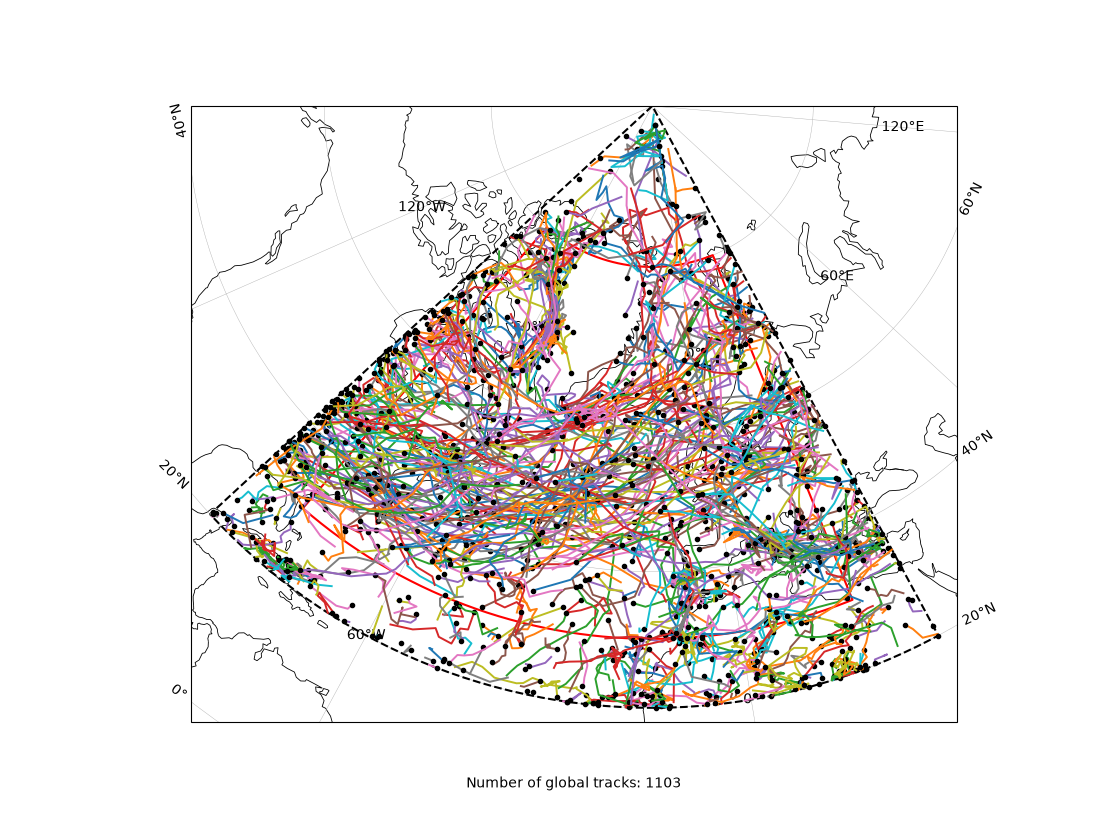

/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


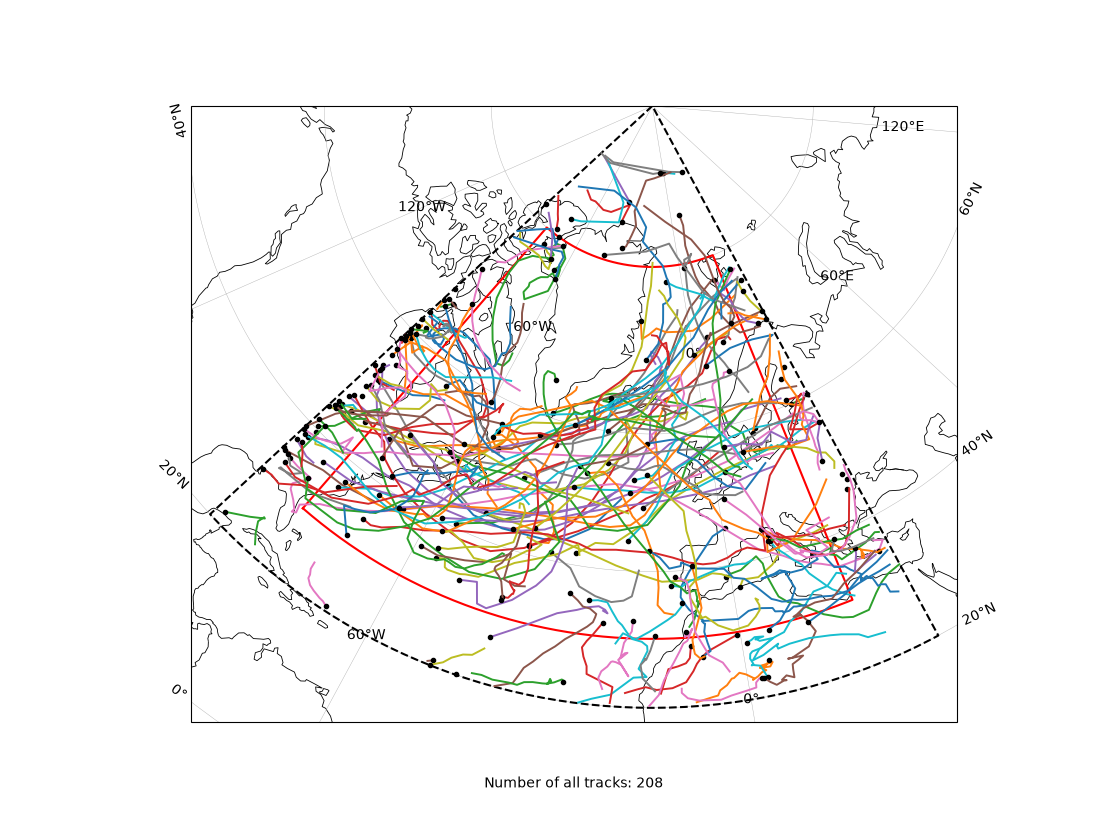

In [9]:
ax = val.plot_regional_tracks(tracks_global, region=REGION, domain=DOMAIN)
ax.set_title("Global Tracks")
ax.text(0.5, -0.1, f"Number of global tracks: {len(tracks_global)}", ha='center', va='center', transform=ax.transAxes) 
plt.show()
ax = val.plot_regional_tracks(tracks_all, region=REGION, domain=DOMAIN)
ax.set_title("All Tracks")
ax.text(0.5, -0.1, f"Number of all tracks: {len(tracks_all)}", ha='center', va='center', transform=ax.transAxes)
plt.show()

In [10]:
tracks_global, summary_global, points_global = pro.postprocess_tracks(tracks_global, **POSTPROCESS_CONFIG)

tracks_all, summary_all, points_all = pro.postprocess_tracks(tracks_all, **POSTPROCESS_CONFIG)

In [11]:
report_validation = pro.filter_report(summary_global)
report_all = pro.filter_report(summary_all)

raw tracks: 1103, kept: 203
raw tracks: 208, kept: 114


In [12]:
print("Validation tracks report:")
print(report_validation)
print("\nAll tracks report:")
print(report_all)

Validation tracks report:
         removed_by_this_criterion  removed_only_by_this_criterion
rsplice                        888                             531
region                         110                               0
edge                           306                              12
peak                             0                               0
time                             0                               0

All tracks report:
         removed_by_this_criterion  removed_only_by_this_criterion
rsplice                         82                              31
region                          32                               0
edge                            38                              12
peak                             0                               0
time                             0                               0


In [13]:
comparison, matches_df = val.compare_to_validation(tracks_all, tracks_global, matching="global_assignment",
                                               max_mean_separation_deg=2.0, min_overlap_fraction=0.6,
                                               variable="vo")

In [14]:
matches_df

,reference_id,candidate_id,overlap_fraction,overlap_count,mean_sep_km,max_sep_km,ref_points,cand_points,ref_peak,cand_peak,n_eligible_candidates,intensity_bias,intensity_rmse
0,700,4200,0.978723,23,53.452728,109.044859,23,24,0.000116,0.000187,1,0.000040,0.000042
1,800,297700,0.666667,14,76.128202,190.908370,28,14,0.000061,0.000090,1,0.000024,0.000026
2,1100,249000,0.888889,16,182.693075,935.205729,20,16,0.000073,0.000107,1,0.000023,0.000025
3,5300,20900,0.933333,14,57.001827,101.876104,14,16,0.000032,0.000055,1,0.000022,0.000022
4,7900,72200,0.857143,18,66.663508,401.897522,24,18,0.000120,0.000203,1,0.000047,0.000050
...,...,...,...,...,...,...,...,...,...,...,...,...,...
69,234600,1606400,0.600000,6,190.220175,320.048364,11,9,0.000044,0.000061,1,0.000021,0.000021
70,234800,1532800,0.947368,9,198.729351,412.938851,10,9,0.000043,0.000060,1,0.000015,0.000015
71,238100,1567400,0.983607,30,205.304269,1618.188262,30,31,0.000124,0.000180,1,0.000027,0.000031
72,246100,1596700,0.814815,11,78.935445,355.643478,11,16,0.000108,0.000169,1,0.000039,0.000042


In [15]:
results_df = pd.Series({
    'Number of global tracks': len(tracks_global),
    'Number of all tracks': len(tracks_all),
    'Number of matched tracks': comparison.tp,
    'Number of missed tracks': comparison.fn,
    'Number of extra tracks': comparison.fp,
    'F1 score': comparison.f1,
    'Precision': comparison.precision,
    'Recall': comparison.recall,
})  

In [16]:
results_df

Number of global tracks     203.000000
Number of all tracks        114.000000
Number of matched tracks     74.000000
Number of missed tracks      40.000000
Number of extra tracks      129.000000
F1 score                      0.466877
Precision                     0.364532
Recall                        0.649123
dtype: float64

In [17]:

# find the verified track ids
verified_candidates = matches_df['candidate_id']
verified_references = matches_df['reference_id']

#filter out the ones we don't keep
global_summary_kept = summary_global[summary_global['keep'] == True]
all_summary_kept = summary_all[summary_all['keep'] == True]

#match the verified tracks to the summary dataframes and the extras
verified_candidate_tracks = global_summary_kept[global_summary_kept['track_id'].isin(verified_candidates)]
extra_tracks = global_summary_kept[~global_summary_kept['track_id'].isin(verified_candidates)]

#find the verified reference tracks and the missed tracks
verified_reference_tracks = all_summary_kept[all_summary_kept['track_id'].isin(verified_references)]
missed_tracks = all_summary_kept[~all_summary_kept['track_id'].isin(verified_references)]


assert len(verified_candidate_tracks) == len(verified_reference_tracks) == comparison.tp
assert len(extra_tracks) == comparison.fp
assert len(missed_tracks) == comparison.fn

Number of extra tracks: 129
Number of extra tracks plotted: 129


/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


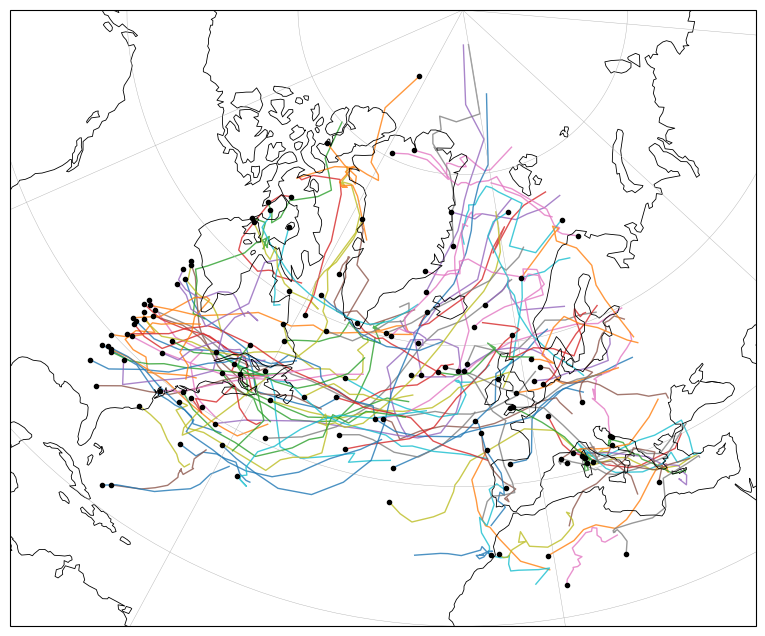

In [18]:
pc = ccrs.PlateCarree()
proj = ccrs.LambertConformal(central_longitude=-15, central_latitude=55)

fig, ax = plt.subplots(figsize=(12, 8), subplot_kw={"projection": proj})
ax.coastlines(linewidth=0.6)
ax.gridlines(linewidth=0.3)
ax.set_extent([DOMAIN[0], DOMAIN[1], DOMAIN[2], 90], crs=pc)
i =0
print(f"Number of extra tracks: {len(extra_tracks)}")
for tr in tracks_global:
    if tr.track_id in extra_tracks['track_id'].values:
        ax.plot(tr.lons, tr.lats, "-", alpha=0.8, lw=1, transform=pc, zorder=0)
        ax.plot(tr.lons[0], tr.lats[0], "k.", ms=6, transform=pc)
        i+=1
print(f"Number of extra tracks plotted: {i}")

Number of missed tracks: 40


/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


Number of missed tracks plotted: 40


/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


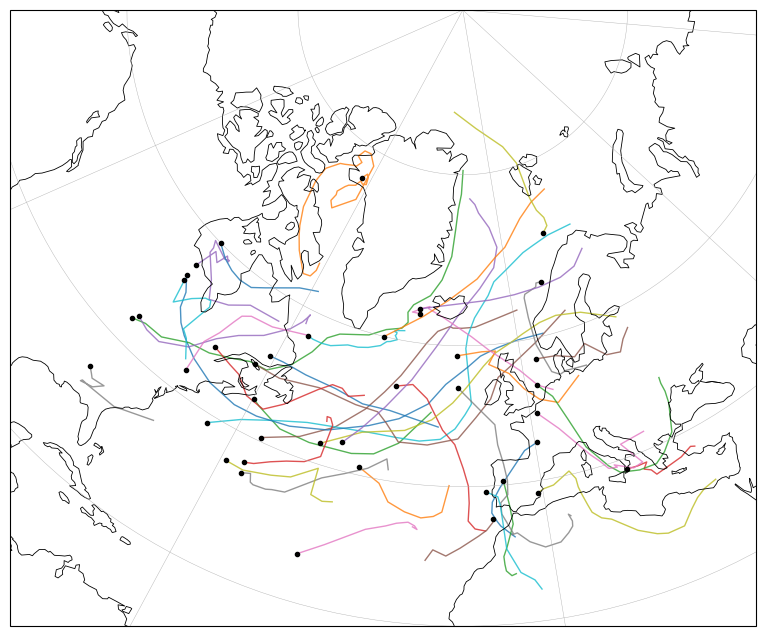

In [19]:
pc = ccrs.PlateCarree()
proj = ccrs.LambertConformal(central_longitude=-15, central_latitude=55)

fig, ax = plt.subplots(figsize=(12, 8), subplot_kw={"projection": proj})
ax.coastlines(linewidth=0.6)
ax.gridlines(linewidth=0.3)
ax.set_extent([DOMAIN[0], DOMAIN[1], DOMAIN[2], 90], crs=pc)
i =0
print(f"Number of missed tracks: {len(missed_tracks)}")
for tr in tracks_all:
    if tr.track_id in missed_tracks['track_id'].values:
        ax.plot(tr.lons, tr.lats, "-", alpha=0.8, lw=1, transform=pc, zorder=0)
        ax.plot(tr.lons[0], tr.lats[0], "k.", ms=6, transform=pc)
        i+=1
print(f"Number of missed tracks plotted: {i}")